In [1]:
import os
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

In [2]:
if os.path.exists("titanic.csv"):
    df = pd.read_csv("titanic.csv")
    print("Dataset loaded from titanic.csv")
else:
    df = sns.load_dataset("titanic")
    df.to_csv("titanic.csv", index=False)
    print("Dataset loaded from Seaborn and saved as titanic.csv")

df.head()

Dataset loaded from titanic.csv


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,female,NaN,0,0,28.4740,S,Third,woman,False,NaN,Southampton,no,True
1,0,2,male,25.0,0,2,24.1156,C,Second,man,True,NaN,Cherbourg,no,False
2,0,3,male,46.0,0,1,14.0627,S,Third,man,True,NaN,Southampton,no,False
3,0,3,female,32.0,0,2,11.5529,S,Third,woman,False,NaN,Southampton,no,False
4,1,1,female,20.0,0,0,364.4553,S,First,woman,False,A,Southampton,yes,True


In [3]:
print("Shape (rows, columns):", df.shape)
df.info()

Shape (rows, columns): (891, 15)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          709 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         215 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 117.0 KB


In [4]:
df.isnull().sum()

survived         0
pclass           0
sex              0
age            182
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           676
embark_town      2
alive            0
alone            0
dtype: int64

In [5]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,709.000000,891.000000,891.000000,891.000000
mean,0.392817,2.300786,28.020451,0.437710,0.359147,39.336083
std,0.488651,0.844938,15.762828,0.923655,0.784021,51.583170
min,0.000000,1.000000,0.500000,0.000000,0.000000,4.000000
25%,0.000000,1.000000,17.000000,0.000000,0.000000,11.690650
50%,0.000000,3.000000,29.000000,0.000000,0.000000,18.297000
75%,1.000000,3.000000,38.000000,1.000000,0.000000,40.981600
max,1.000000,3.000000,76.000000,5.000000,5.000000,364.455300


In [ ]:
# Age: fill missing values with median age
df["age"] = df["age"].fillna(df["age"].median())

# Embarked: fill missing values with the most common port
df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])
df["embark_town"] = df["embark_town"].fillna(df["embark_town"].mode()[0])

# Deck has too many missing values, so drop it
if "deck" in df.columns:
    df = df.drop(columns=["deck"])

# New columns for analysis
df["age_group"] = pd.cut(df["age"],
                         bins=[0, 12, 18, 35, 60, 100],
                         labels=["Child", "Teen", "Young Adult", "Adult", "Senior"])
df["family_size"] = df["sibsp"] + df["parch"] + 1
df["sex_num"] = df["sex"].map({"male": 0, "female": 1})

print("Missing values left:", int(df.isnull().sum().sum()))

Missing values left: 0


In [7]:
print("Overall survival rate: {:.1f}%".format(df["survived"].mean() * 100))

Overall survival rate: 39.3%


In [8]:
(df.groupby("pclass")["survived"].mean() * 100).round(1)

pclass
1    57.1
2    40.6
3    30.7
Name: survived, dtype: float64

In [9]:
(df.groupby("sex")["survived"].mean() * 100).round(1)

sex
female    69.3
male      22.3
Name: survived, dtype: float64

In [10]:
(df.groupby("age_group", observed=True)["survived"].mean() * 100).round(1)

age_group
Child          52.5
Teen           29.5
Young Adult    35.8
Adult          42.9
Senior         41.7
Name: survived, dtype: float64

In [11]:
(df.groupby("embarked")["survived"].mean() * 100).round(1)

embarked
C    44.5
Q    27.8
S    39.0
Name: survived, dtype: float64

In [12]:
(df.groupby(["pclass", "sex"])["survived"].mean() * 100).round(1)

pclass  sex   
1       female    97.5
        male      34.7
2       female    89.7
        male      16.2
3       female    50.5
        male      18.8
Name: survived, dtype: float64

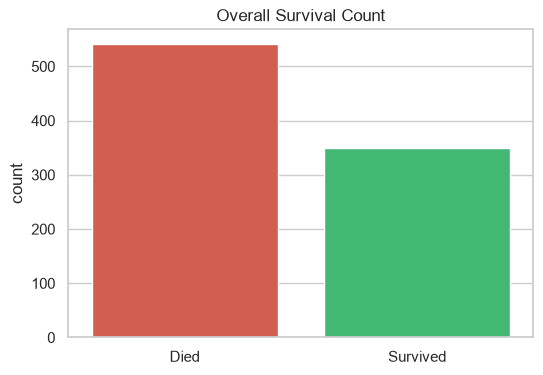

In [13]:
plt.figure(figsize=(6, 4))
sns.countplot(x="survived", data=df, palette=["#e74c3c", "#2ecc71"])
plt.title("Overall Survival Count")
plt.xticks([0, 1], ["Died", "Survived"])
plt.xlabel("")
plt.show()

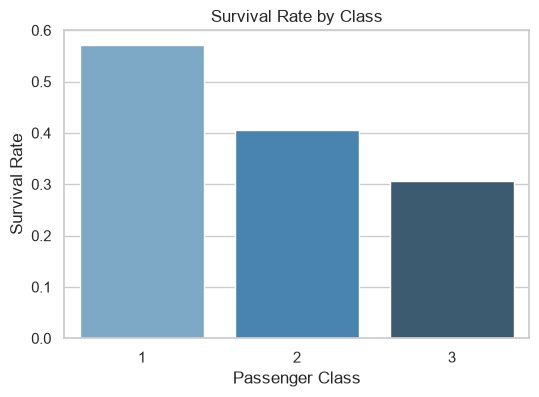

In [14]:
plt.figure(figsize=(6, 4))
sns.barplot(x="pclass", y="survived", data=df, errorbar=None, palette="Blues_d")
plt.title("Survival Rate by Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.show()

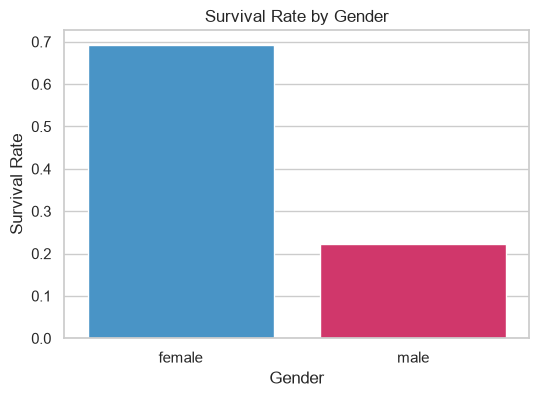

In [15]:
plt.figure(figsize=(6, 4))
sns.barplot(x="sex", y="survived", data=df, errorbar=None, palette=["#3498db", "#e91e63"])
plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate")
plt.show()

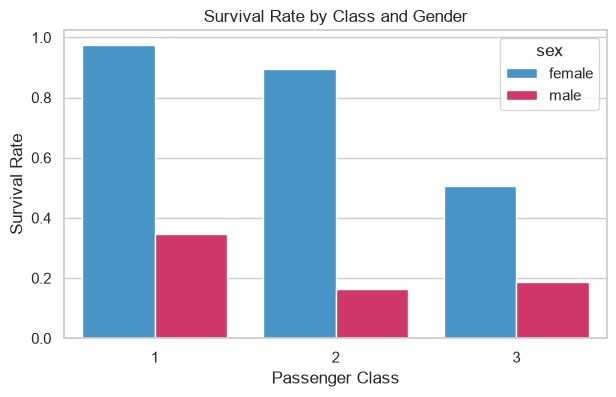

In [16]:
plt.figure(figsize=(7, 4))
sns.barplot(x="pclass", y="survived", hue="sex", data=df, errorbar=None,
            palette=["#3498db", "#e91e63"])
plt.title("Survival Rate by Class and Gender")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.show()

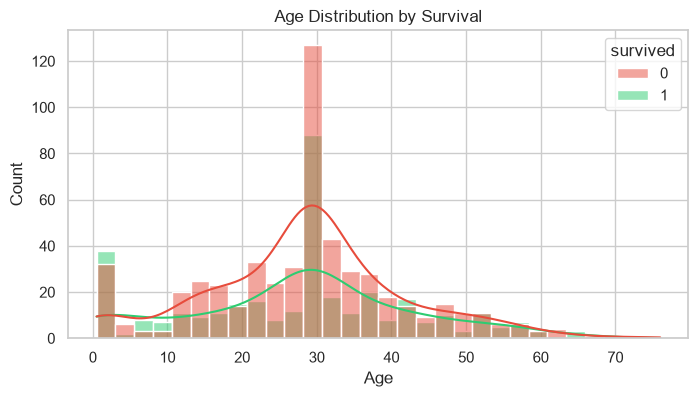

In [17]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="age", hue="survived", bins=30, kde=True,
             palette=["#e74c3c", "#2ecc71"])
plt.title("Age Distribution by Survival")
plt.xlabel("Age")
plt.show()

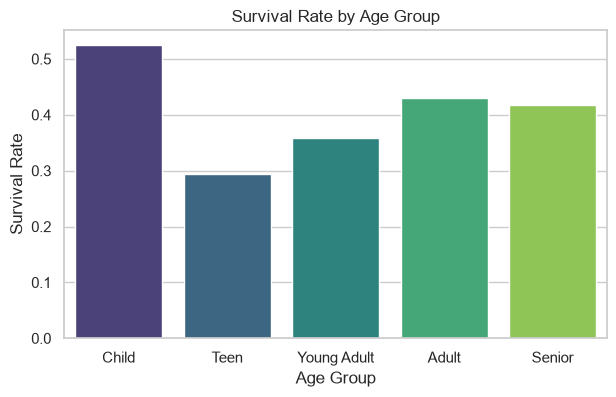

In [18]:
plt.figure(figsize=(7, 4))
sns.barplot(x="age_group", y="survived", data=df, errorbar=None, palette="viridis")
plt.title("Survival Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate")
plt.show()

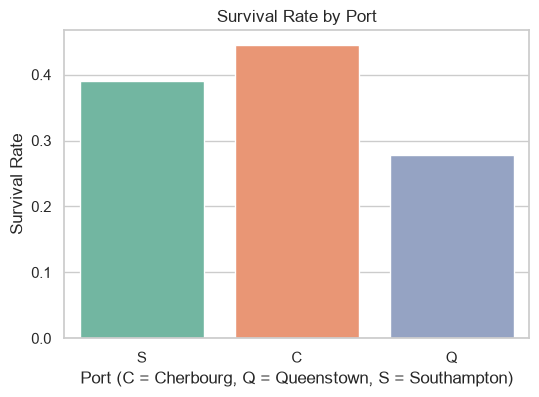

In [19]:
plt.figure(figsize=(6, 4))
sns.barplot(x="embarked", y="survived", data=df, errorbar=None, palette="Set2")
plt.title("Survival Rate by Port")
plt.xlabel("Port (C = Cherbourg, Q = Queenstown, S = Southampton)")
plt.ylabel("Survival Rate")
plt.show()

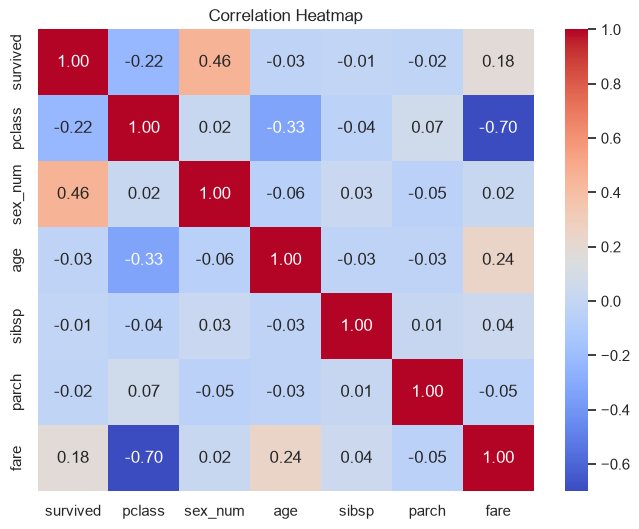

In [20]:
corr_cols = ["survived", "pclass", "sex_num", "age", "sibsp", "parch", "fare"]

plt.figure(figsize=(8, 6))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

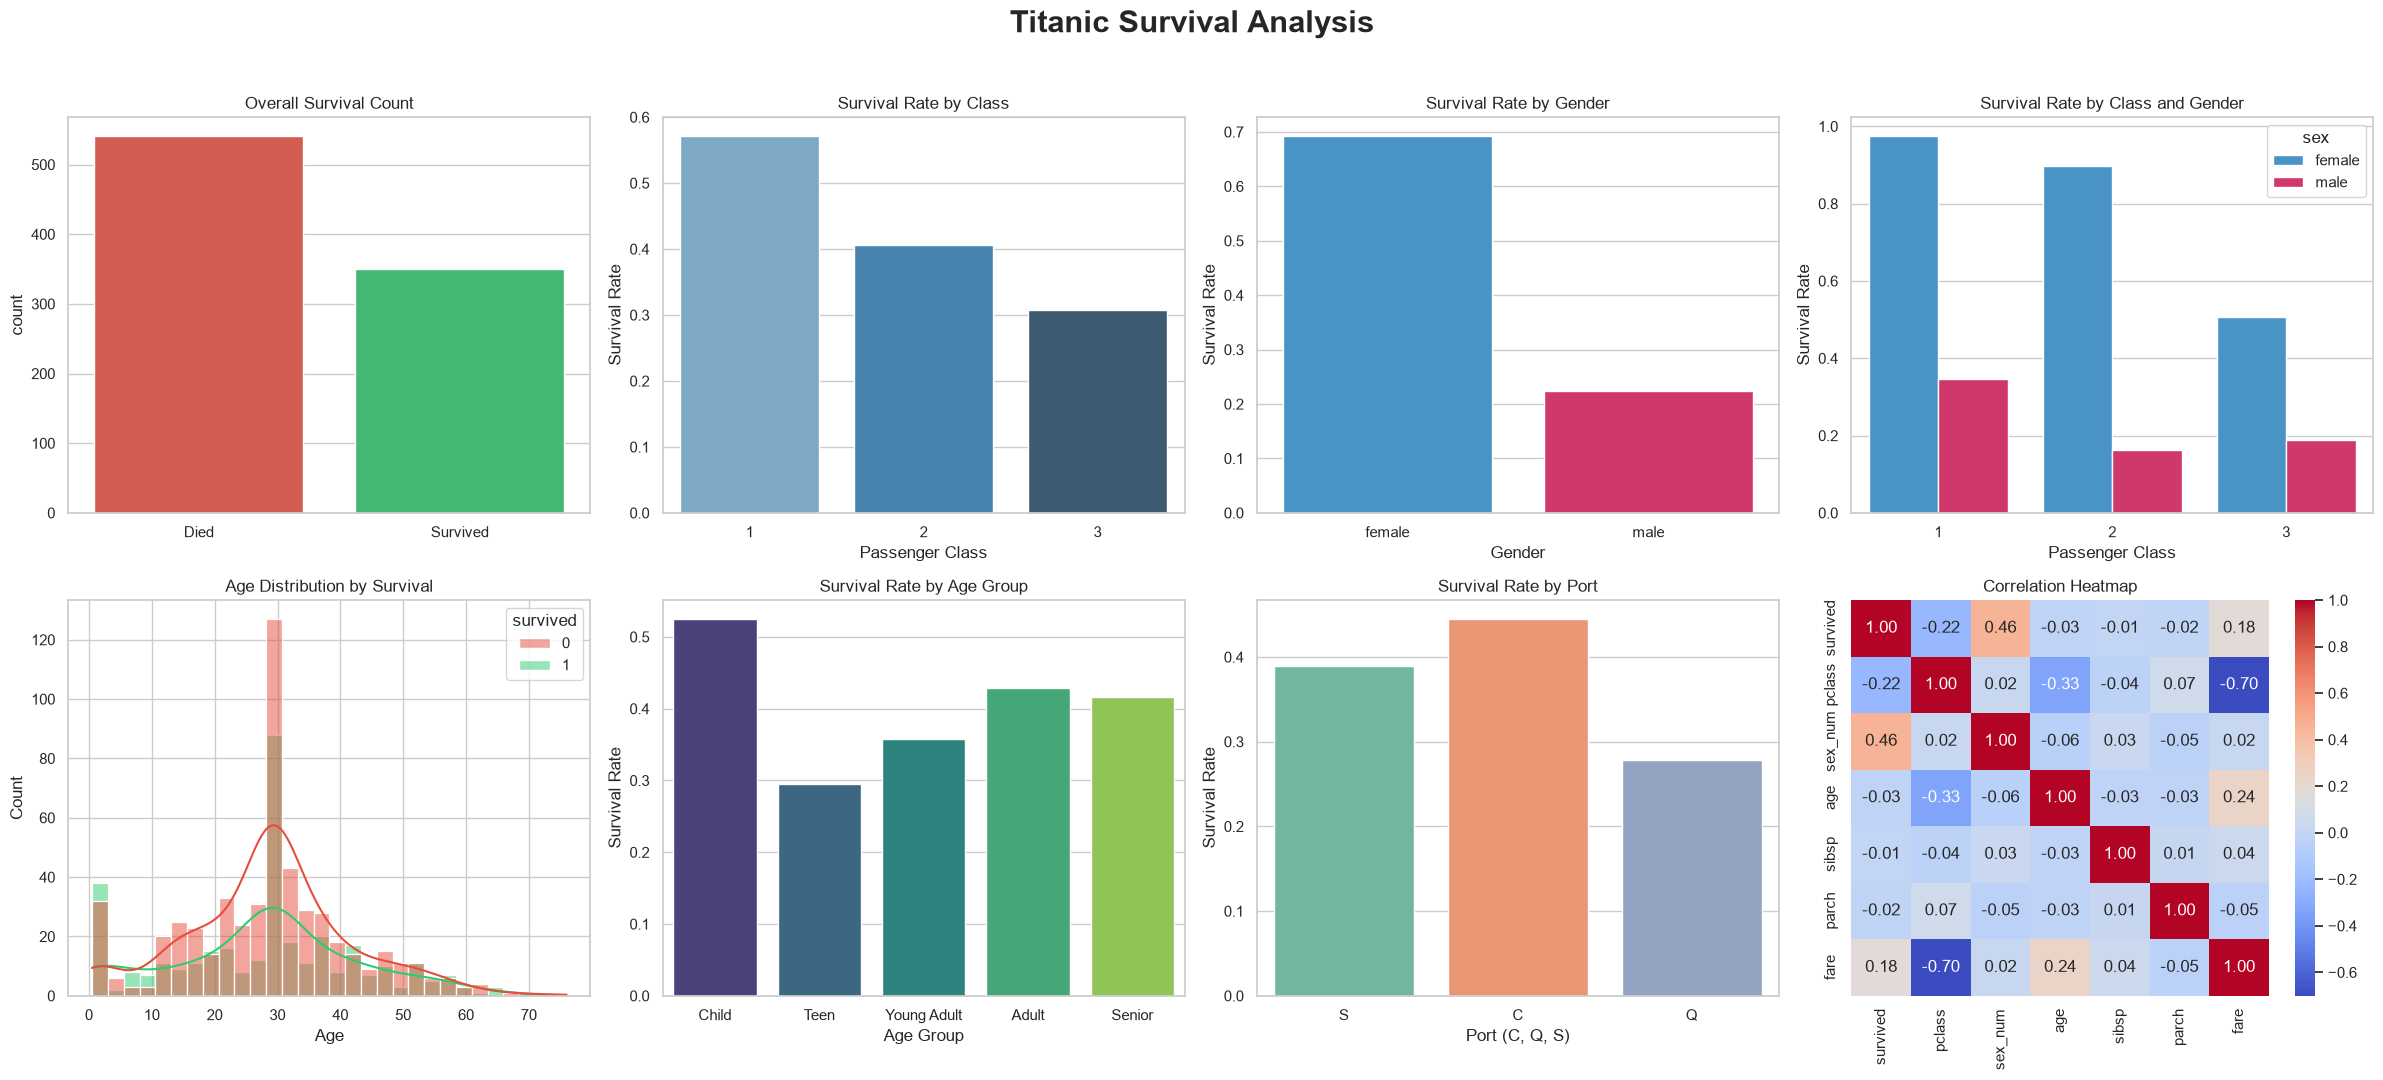

Charts saved as output.png


In [21]:
fig, axes = plt.subplots(2, 4, figsize=(24, 11))
fig.suptitle("Titanic Survival Analysis", fontsize=22, fontweight="bold")

sns.countplot(x="survived", data=df, ax=axes[0, 0], palette=["#e74c3c", "#2ecc71"])
axes[0, 0].set_title("Overall Survival Count")
axes[0, 0].set_xticks([0, 1])
axes[0, 0].set_xticklabels(["Died", "Survived"])
axes[0, 0].set_xlabel("")

sns.barplot(x="pclass", y="survived", data=df, ax=axes[0, 1], errorbar=None, palette="Blues_d")
axes[0, 1].set_title("Survival Rate by Class")
axes[0, 1].set_xlabel("Passenger Class")
axes[0, 1].set_ylabel("Survival Rate")

sns.barplot(x="sex", y="survived", data=df, ax=axes[0, 2], errorbar=None,
            palette=["#3498db", "#e91e63"])
axes[0, 2].set_title("Survival Rate by Gender")
axes[0, 2].set_xlabel("Gender")
axes[0, 2].set_ylabel("Survival Rate")

sns.barplot(x="pclass", y="survived", hue="sex", data=df, ax=axes[0, 3], errorbar=None,
            palette=["#3498db", "#e91e63"])
axes[0, 3].set_title("Survival Rate by Class and Gender")
axes[0, 3].set_xlabel("Passenger Class")
axes[0, 3].set_ylabel("Survival Rate")

sns.histplot(data=df, x="age", hue="survived", bins=30, kde=True, ax=axes[1, 0],
             palette=["#e74c3c", "#2ecc71"])
axes[1, 0].set_title("Age Distribution by Survival")
axes[1, 0].set_xlabel("Age")

sns.barplot(x="age_group", y="survived", data=df, ax=axes[1, 1], errorbar=None, palette="viridis")
axes[1, 1].set_title("Survival Rate by Age Group")
axes[1, 1].set_xlabel("Age Group")
axes[1, 1].set_ylabel("Survival Rate")

sns.barplot(x="embarked", y="survived", data=df, ax=axes[1, 2], errorbar=None, palette="Set2")
axes[1, 2].set_title("Survival Rate by Port")
axes[1, 2].set_xlabel("Port (C, Q, S)")
axes[1, 2].set_ylabel("Survival Rate")

sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1, 3])
axes[1, 3].set_title("Correlation Heatmap")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("output.png", dpi=150, bbox_inches="tight")
plt.show()
print("Charts saved as output.png")

## Key Findings
1. Women survived far more than men.
2. 1st class passengers had the highest survival rate; 3rd class the lowest.
3. Children had a better chance of survival than other age groups.
4. Higher fare (wealthier passengers) is linked with higher survival.
5. Gender and class together were the strongest survival factors.